In [1]:
import os
import sys
import re
import ROOT
import numpy as np
import pandas as pd
import cmath
from tabulate import tabulate
from gc import collect
ROOT.gROOT.SetStyle("ATLAS")
ROOT.gROOT.SetBatch(True) 
from IPython.display import Image, display

plots_dir = "./plots"
tables_dir = "./tables"
os.makedirs(plots_dir, exist_ok=True)
os.makedirs(tables_dir, exist_ok=True)

M_min, M_max, M_step = 1000, 2000, 50
mass_points = range(M_min, M_max + M_step, M_step)

## Cross Section Data

### LHC SUSY Cross Section Working Group

https://twiki.cern.ch/twiki/bin/view/LHCPhysics/SUSYCrossSections13x6TeVn2x1wino

PDF is PDF4LHC21_40.

13.6 TeV at NNLO+NNLL accuracy in EW.

In [2]:
def read_lhc_wdg(filepath, proc=None):
    df_i = pd.read_csv(filepath)
    df_o = pd.DataFrame()
    df_o["mass"] = df_i["mass"].astype(int)
    proc_map = {"sigp_sig0":"n2x1p", "sigm_sig0":"n2x1m", "sigp_sigm":"x1px1m"}
    if proc is None:
        df_o["xsec"] = df_i["n2x1p_xsec"] + df_i["n2x1m_xsec"] + df_i["x1px1m_xsec"] 
        df_o["xsec_y_err_high"] = (
            (np.hypot(df_i["n2x1p_scale_unc_high"], df_i["n2x1p_pdf_unc_high"]) * df_i["n2x1p_xsec"] / 100) +
            (np.hypot(df_i["n2x1m_scale_unc_high"], df_i["n2x1m_pdf_unc_high"]) * df_i["n2x1m_xsec"] / 100) +
            (np.hypot(df_i["x1px1m_scale_unc_high"], df_i["x1px1m_pdf_unc_high"]) * df_i["x1px1m_xsec"] / 100)
        )
        df_o["xsec_y_err_low"] = (
            (np.hypot(df_i["n2x1p_scale_unc_low"], df_i["n2x1p_pdf_unc_low"]) * df_i["n2x1p_xsec"] / 100) +
            (np.hypot(df_i["n2x1m_scale_unc_low"], df_i["n2x1m_pdf_unc_low"]) * df_i["n2x1m_xsec"] / 100) +
            (np.hypot(df_i["x1px1m_scale_unc_low"], df_i["x1px1m_pdf_unc_low"]) * df_i["x1px1m_xsec"] / 100)
        )
        return df_o
    else:
        for proc_key, pv in proc_map.items():
            if proc == proc_key:
                df_o["xsec"] = df_i[f"{pv}_xsec"]
                df_o["xsec_y_err_high"] = np.hypot(df_i[f"{pv}_scale_unc_high"], df_i[f"{pv}_pdf_unc_high"]) * df_i[f"{pv}_xsec"] / 100
                df_o["xsec_y_err_low"] = np.hypot(df_i[f"{pv}_scale_unc_low"], df_i[f"{pv}_pdf_unc_low"]) * df_i[f"{pv}_xsec"] / 100
                return df_o

df_13x6TeV_nnlo_nnll = read_lhc_wdg("./cross_section/susy_nnlo_nnll_13x6TeV.csv")
display(df_13x6TeV_nnlo_nnll)
df_13x6TeV_nnlo_nnll.to_csv("./tables/xsec_13p6TeV_nnlo_nnll.csv", index=False)

,mass,xsec,xsec_y_err_high,xsec_y_err_low
0,90,55950.000000,1995.573597,2402.851668
1,100,37755.000000,1327.496297,1531.788565
2,150,8648.000000,298.887162,313.323557
3,200,3027.700000,114.805369,116.442927
4,250,1315.200000,54.117536,54.408440
5,300,652.200000,29.480302,29.521183
6,350,353.810000,17.512272,17.494625
7,400,204.800000,11.104171,11.096429
8,450,124.560000,7.321141,7.316685
9,500,78.730000,4.967983,4.963226


In [3]:
df_13TeV_nnlo_nnll = read_lhc_wdg("./cross_section/susy_nnlo_nnll_13TeV.csv")
display(df_13TeV_nnlo_nnll)
df_13TeV_nnlo_nnll.to_csv("./tables/xsec_13TeV_nnlo_nnll.csv", index=False)

,mass,xsec,xsec_y_err_high,xsec_y_err_low
0,90,52840.000000,1899.473698,2262.016310
1,100,35591.000000,1249.127478,1435.068158
2,150,8103.000000,287.487817,299.308391
3,200,2821.100000,106.838725,108.442922
4,250,1218.300000,51.410429,51.650403
5,300,600.700000,27.874783,27.874783
6,350,324.000000,16.564762,16.549133
7,400,186.510000,10.373706,10.366741
8,450,112.770000,6.851339,6.844373
9,500,70.860000,4.638652,4.634479


In [4]:
susy_13TeV_nlo = pd.read_csv("./cross_section/susy_nlo_nll_13TeV.csv")
df_13TeV_nlo_nll = pd.DataFrame()
df_13TeV_nlo_nll["mass"] = susy_13TeV_nlo["mass"].astype(int)
df_13TeV_nlo_nll["xsec"] = susy_13TeV_nlo["n2x1_xsec"] + susy_13TeV_nlo["x1px1m_xsec"]
df_13TeV_nlo_nll["xsec_y_err_high"] = susy_13TeV_nlo["n2x1_unc"] + susy_13TeV_nlo["x1px1m_unc"]
df_13TeV_nlo_nll["xsec_y_err_low"] = susy_13TeV_nlo["n2x1_unc"] + susy_13TeV_nlo["x1px1m_unc"]
display(df_13TeV_nlo_nll)
df_13TeV_nlo_nll.to_csv("./tables/xsec_13TeV_nlo_nll.csv", index=False)

,mass,xsec,xsec_y_err_high,xsec_y_err_low
0,100,34282.000000,1492.580000,1492.580000
1,125,15125.320000,707.073000,707.073000
2,150,7793.170000,391.379000,391.379000
3,175,4435.700000,237.653200,237.653200
4,200,2709.959000,155.057100,155.057100
...,...,...,...,...
72,1900,0.014808,0.004015,0.004015
73,1925,0.013008,0.003636,0.003636
74,1950,0.011457,0.003341,0.003341
75,1975,0.009934,0.003088,0.003088


## Numerical calculations with MG5 at NLO+PS accuracy

This function reads the parton_sytematics.txt file generated by MadGraph5_aMC@NLO.
It extracts the original cross-section, scale variation, central scheme variation, and PDF variation.
Returns a dictionary with these values and the total uncertainty.
These setting has to be made in the run_card.dat file before generating the events:
- set use_syst True / set store_rwgt_info True for NLO
- set systematics_program systematics
- set systematics_arguments ['--together=mur,muf,dyn', '--pdf=errorset']

In [5]:
import re
import numpy as np

def read_parton_systematics(filepath, use_fp = False):
    pct_re = re.compile(r'([+-]?\s*\d+(?:\.\d+)?)\s*%')
    xsec_pb = None
    with open(filepath) as f:
        for line in f:
            if "original cross-section" in line:
                xsec_pb = float(line.split(":", 1)[1].strip())
            if "scale variation" in line:
                nums = pct_re.findall(line)
                if nums:
                    scale = [float(n.replace(" ", ""))/100.0 for n in nums]
            if "central scheme variation" in line:
                nums = pct_re.findall(line)
                if nums:
                    scheme = [float(n.replace(" ", ""))/100.0 for n in nums]
            if "PDF variation" in line:
                nums = pct_re.findall(line)
                if nums:
                    pdf = [float(n.replace(" ", ""))/100.0 for n in nums]

    # basic checks
    if xsec_pb is None:
        raise ValueError(f"original cross-section not found in file: {filepath}")

    # set default zero-uncertainties if any systematics block missing
    if scale is None:
        scale = [0.0, 0.0]
    if scheme is None:
        scheme = [0.0, 0.0]
    if pdf is None:
        pdf = [0.0, 0.0]
    
    # relative uncertainties calculations:
    up_rel = np.sqrt(scale[0]**2 + scheme[0]**2 + pdf[0]**2)
    down_rel = np.sqrt(scale[1]**2 + scheme[1]**2 + pdf[1]**2)

    # convert xsec to desried units
    if use_fp:
        xsec_converted = xsec_pb * 1000.0
    else:
        xsec_converted = xsec_pb * 1.0


    # upper and lower cross section values
    xsec_up = xsec_converted * (1.0 + up_rel)
    xsec_down = xsec_converted * (1.0 - down_rel)

    # absolute +delta and -delta values
    xsec_up_abs = xsec_converted * up_rel
    xsec_down_abs = xsec_converted * down_rel

    return {
        "Cross Section" : xsec_converted,
        "Scale Variation": scale,
        "Central Scheme Variation": scheme,
        "PDF Variation": pdf,
        "Total Uncertainty (relative)": [up_rel, down_rel],
        "Total Uncertainty (absolute)": [xsec_up_abs, xsec_down_abs],
        "Upper/Lower Cross Sections": [xsec_up, xsec_down]
    }


In [6]:
def get_results(base_dir, mass_points = list(range(1000, 2000 + 50, 50))):
    x_val, y_val, y_err_low, y_err_high = [], [], [], []
    
    for idx, mass in enumerate(mass_points):
        x_val.append(mass)
        run_dir = f"M{mass}"
        file_path = f"{base_dir}/{run_dir}/parton_systematics.log"
        systematics = read_parton_systematics(file_path, use_fp = True)
        y_val.append(systematics["Cross Section"])
        y_err_low.append(systematics["Total Uncertainty (absolute)"][0])
        y_err_high.append(systematics["Total Uncertainty (absolute)"][1])

    n = len(x_val)
    return {
        'n': n,
        'x' : np.array(x_val, dtype='double'), 
        'y' : np.array(y_val, dtype='double'), 
        'exl' : np.zeros(n, dtype='double'),
        'exh' : np.zeros(n, dtype='double'),
        'eyl' : np.array(y_err_low, dtype='double'), 
        'eyh' : np.array(y_err_high, dtype='double'), 
    } 

Save cross sections results into csv tables for later use.

For the cross section results, we need two tables, one with systematics, and one without.

For the one with systematics, we need the mass, lo_xsec, lo_xsec_y_low, lo_xsec_y_high, nlo_xsec, ..., k_factor, old_lo_xsec, old_lo_xsec_y_low, ..., diff_lo

In [7]:
lo_dir = "./cross_section/LO/total/Events"
nlo_dir = "./cross_section/NLO/total/Events"
nlo_13TeV_dir = "./cross_section/NLO/total_13TeV/Events"
old_lo_dir =  "./cross_section/LO_old/total/Events"

# m = list(range(300, 2000 + 50, 50))
# df_13x6TeV_lo = pd.DataFrame()
# df_13x6TeV_lo["mass"] = np.array(m, dtype='int')
# df_13x6TeV_lo["xsec"] = get_results(lo_dir)["y"]
# df_13x6TeV_lo["xsec_y_err_high"] = get_results(lo_dir)["eyl"]
# df_13x6TeV_lo["xsec_y_err_low"] = get_results(lo_dir)["eyh"]

m = list(range(300, 2000 + 50, 50))
df_13x6TeV_nlo_ps = pd.DataFrame()
df_13x6TeV_nlo_ps["mass"] = np.array(m, dtype='int')
df_13x6TeV_nlo_ps["xsec"] = get_results(nlo_dir, mass_points=m)["y"]
df_13x6TeV_nlo_ps["xsec_y_err_high"] = get_results(nlo_dir, mass_points=m)["eyl"]
df_13x6TeV_nlo_ps["xsec_y_err_low"] = get_results(nlo_dir, mass_points=m)["eyh"]
df_13x6TeV_nlo_ps.to_csv("./tables/xsec_13p6TeV_nlo_ps.csv", index=False)

m = list(range(300, 2000 + 50, 50))
df_13TeV_nlo_ps = pd.DataFrame()
df_13TeV_nlo_ps["mass"] = np.array(m, dtype='int')
df_13TeV_nlo_ps["xsec"] = get_results(nlo_13TeV_dir, mass_points=m)["y"]
df_13TeV_nlo_ps["xsec_y_err_high"] = get_results(nlo_13TeV_dir, mass_points=m)["eyl"]
df_13TeV_nlo_ps["xsec_y_err_low"] = get_results(nlo_13TeV_dir, mass_points=m)["eyh"]
df_13TeV_nlo_ps.to_csv("./tables/xsec_13TeV_nlo_ps.csv", index=False)

# df_13x6TeV_nlo_ps["nlo_xsec_13TeV"] = get_results(nlo_13TeV_dir, mass_points=m)["y"]
# df_13x6TeV_nlo_ps["nlo_xsec_13TeV_y_err_low"] = get_results(nlo_13TeV_dir, mass_points=m)["eyl"]
# df_13x6TeV_nlo_ps["nlo_xsec_13TeV_y_err_high"] = get_results(nlo_13TeV_dir, mass_points=m)["eyh"]

# df_xsec["k_factor"] = df_xsec["nlo_xsec"] / df_xsec["lo_xsec"]
# df_xsec["k_factor_y_err_low"] = df_xsec["k_factor"] * np.sqrt((df_xsec["nlo_xsec_y_err_low"]/df_xsec["nlo_xsec"])**2 + (df_xsec["lo_xsec_y_err_high"]/df_xsec["lo_xsec"])**2)
# df_xsec["k_factor_y_err_high"] = df_xsec["k_factor"] * np.sqrt((df_xsec["nlo_xsec_y_err_high"]/df_xsec["nlo_xsec"])**2 + (df_xsec["lo_xsec_y_err_low"]/df_xsec["lo_xsec"])**2)

# df_xsec["old_lo_xsec"] = get_results(old_lo_dir)["y"]
# df_xsec["old_lo_xsec_y_err_low"] = get_results(old_lo_dir)["eyl"]
# df_xsec["old_lo_xsec_y_err_high"] = get_results(old_lo_dir)["eyh"]

# df_xsec["diff_lo"] = abs(df_xsec["lo_xsec"] - df_xsec["old_lo_xsec"]) / ((df_xsec["lo_xsec"] + df_xsec["old_lo_xsec"])/2) * 100

display(df_13x6TeV_nlo_ps)
df_13x6TeV_nlo_ps.to_csv(os.path.join(tables_dir, "signal_cross_sections.csv"), index=False)

,mass,xsec,xsec_y_err_high,xsec_y_err_low
0,300,648.165889,41.822173,17.950451
1,350,353.520834,9.079981,10.555661
2,400,205.363866,13.449373,6.621034
3,450,125.311636,8.405581,4.552125
4,500,80.133261,2.431936,2.992181
5,550,51.943673,1.697064,2.100825
6,600,34.897060,1.123024,1.401364
7,650,23.795786,0.800055,1.002277
8,700,16.571393,0.599255,0.754625
9,750,11.762050,0.460523,0.581480


here we can prepare a latex table

In [8]:
# error formatting for the latex table
def fmt_with_err(val, low, high, digits=3):
    return f"${val:.{digits}f}^{{+{high:.{digits}f}}}_{{-{low:.{digits}f}}}$"

df_latex = pd.DataFrame()
df_latex["$m_N$ [GeV]"] = df_13x6TeV_nlo_ps["mass"].astype(int)
# df_latex["$\sigma_\mathrm{{LO}}$ [fb]"] = df_xsec.apply(lambda r: fmt_with_err(r.lo_xsec, r.lo_xsec_y_err_low, r.lo_xsec_y_err_high), axis=1)
df_latex["$\sigma_\mathrm{{NLO}}$ [fb]"] = df_13x6TeV_nlo_ps.apply(lambda r: fmt_with_err(r.nlo_xsec, r.nlo_xsec_y_err_low, r.nlo_xsec_y_err_high), axis=1)
# df_latex["$k$"] = df_xsec.apply(lambda r: fmt_with_err(r.k_factor, r.k_factor_y_err_low, r.k_factor_y_err_high), axis=1)
print(df_latex.to_latex(index=False, escape=False))

<>:8: SyntaxWarning: invalid escape sequence '\s'
<>:8: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_1694/846621233.py:8: SyntaxWarning: invalid escape sequence '\s'
  df_latex["$\sigma_\mathrm{{NLO}}$ [fb]"] = df_13x6TeV_nlo_ps.apply(lambda r: fmt_with_err(r.nlo_xsec, r.nlo_xsec_y_err_low, r.nlo_xsec_y_err_high), axis=1)
/tmp/ipykernel_1694/846621233.py:8: SyntaxWarning: invalid escape sequence '\s'
  df_latex["$\sigma_\mathrm{{NLO}}$ [fb]"] = df_13x6TeV_nlo_ps.apply(lambda r: fmt_with_err(r.nlo_xsec, r.nlo_xsec_y_err_low, r.nlo_xsec_y_err_high), axis=1)


AttributeError: 'Series' object has no attribute 'nlo_xsec'

## Comparison table

In [ ]:
m = list(range(300, 2000 + 50, 50))
# df_13x6TeV_lo = df_13x6TeV_lo.copy().set_index("mass").reindex(m).reset_index()
df_13x6TeV_nlo_ps = df_13x6TeV_nlo_ps.copy().set_index("mass").reindex(m).reset_index()
df_13x6TeV_nnlo_nnll = df_13x6TeV_nnlo_nnll.copy().set_index("mass").reindex(m).reset_index()
df_13TeV_nnlo_nnll   = df_13TeV_nnlo_nnll.copy().set_index("mass").reindex(m).reset_index()
df_13TeV_nlo_nll    = df_13TeV_nlo_nll.copy().set_index("mass").reindex(m).reset_index()

df_comparison = pd.DataFrame()
df_comparison["mass"] = df_13x6TeV_nlo_ps["mass"]

# 13.6 TeV 
df_comparison["13p6_nnlo_nnll_xsec"] = df_13x6TeV_nnlo_nnll["xsec"]
df_comparison["13p6_nnlo_nnll_xsec_y_err_low"] = df_13x6TeV_nnlo_nnll["xsec_y_err_low"]
df_comparison["13p6_nnlo_nnll_xsec_y_err_high"] = df_13x6TeV_nnlo_nnll["xsec_y_err_high"]
df_comparison["13p6_nlo_ps_xsec"] = df_13x6TeV_nlo_ps["xsec"] 
df_comparison["13p6_nlo_ps_xsec_y_err_low"] = df_13x6TeV_nlo_ps["xsec_y_err_low"] 
df_comparison["13p6_nlo_ps_xsec_y_err_high"] = df_13x6TeV_nlo_ps["xsec_y_err_high"]
# df_comparison["13p6_lo_xsec"] = df_13x6TeV_lo["xsec"] 
# df_comparison["13p6_lo_xsec_y_err_low"] = df_13x6TeV_lo["xsec_y_err_low"] 
# df_comparison["13p6_lo_xsec_y_err_high"] = df_13x6TeV_lo["xsec_y_err_high"]

# 13 TeV
df_comparison["13_nnlo_nnnl_xsec"] = df_13TeV_nnlo_nnll["xsec"]
df_comparison["13_nnlo_nnnl_xsec_y_err_low"] = df_13TeV_nnlo_nnll["xsec_y_err_low"]
df_comparison["13_nnlo_nnnl_xsec_y_err_high"] = df_13TeV_nnlo_nnll["xsec_y_err_high"]
df_comparison["13_nlo_nnl_xsec"] = df_13TeV_nlo_nll["xsec"]
df_comparison["13_nlo_nnl_xsec_y_err_low"] = df_13TeV_nlo_nll["xsec_y_err_low"]
df_comparison["13_nlo_nnl_xsec_y_err_high"] = df_13TeV_nlo_nll["xsec_y_err_high"]
df_comparison["13_nlo_ps_xsec"] = df_13TeV_nlo_ps["xsec"]
df_comparison["13_nlo_ps_xsec_y_err_low"] = df_13TeV_nlo_ps["xsec_y_err_low"]
df_comparison["13_nlo_ps_xsec_y_err_high"] = df_13TeV_nlo_ps["xsec_y_err_high"]

display(df_comparison)

# df_comparison_latex = pd.DataFrame()
# df_comparison_latex["$m_N$ [GeV]"] = df_comparison["mass"]
# # 13 TeV
# df_comparison_latex["13 TeV (MG5)"] = df_comparison.apply(lambda r: fmt_with_err(r.xsec_13TeV_mg5, r.xsec_13TeV_mg5_y_err_low, r.xsec_13TeV_mg5_y_err_high), axis=1)
# df_comparison_latex["13 TeV (NLO)"] = df_comparison.apply(lambda r: fmt_with_err(r.xsec_13TeV_susy_nlo, r.xsec_13TeV_susy_nlo_y_err_low, r.xsec_13TeV_susy_nlo_y_err_high), axis=1)
# df_comparison_latex["13 TeV (NNLO)"] = df_comparison.apply(lambda r: fmt_with_err(r.xsec_13TeV_susy_nnlo, r.xsec_13TeV_susy_nnlo_y_err_low, r.xsec_13TeV_susy_nnlo_y_err_high), axis=1)
# # 13.6 TeV
# df_comparison_latex["13.6 TeV (MG5)"] = df_comparison.apply(lambda r: fmt_with_err(r.xsec_13x6TeV_mg5, r.xsec_13x6TeV_mg5_y_err_low, r.xsec_13x6TeV_mg5_y_err_high), axis=1)
# df_comparison_latex["13.6 TeV (NNLO)"] = df_comparison.apply(lambda r: fmt_with_err(r.xsec_13x6TeV_susy_nnlo, r.xsec_13x6TeV_susy_nnlo_y_err_low, r.xsec_13x6TeV_susy_nnlo_y_err_high), axis=1)
# print(df_comparison_latex.to_latex(index=False, escape=False))


,mass,13p6_nnlo_nnll_xsec,13p6_nnlo_nnll_xsec_y_err_low,13p6_nnlo_nnll_xsec_y_err_high,13p6_nlo_ps_xsec,13p6_nlo_ps_xsec_y_err_low,13p6_nlo_ps_xsec_y_err_high,13_nnlo_nnnl_xsec,13_nnlo_nnnl_xsec_y_err_low,13_nnlo_nnnl_xsec_y_err_high,13_nlo_nnl_xsec,13_nlo_nnl_xsec_y_err_low,13_nlo_nnl_xsec_y_err_high,13_nlo_ps_xsec,13_nlo_ps_xsec_y_err_low,13_nlo_ps_xsec_y_err_high
0,300,652.200000,29.521183,29.480302,648.165889,17.950451,41.822173,600.700000,27.874783,27.874783,577.095000,39.804000,39.804000,600.877571,17.658032,33.657137
1,350,353.810000,17.494625,17.512272,353.520834,10.555661,9.079981,324.000000,16.549133,16.564762,311.638000,23.206510,23.206510,324.463493,9.828673,8.390817
2,400,204.800000,11.096429,11.104171,205.363866,6.621034,13.449373,186.510000,10.366741,10.373706,179.644100,14.344190,14.344190,187.955641,6.470535,5.396979
3,450,124.560000,7.316685,7.321141,125.311636,4.552125,8.405581,112.770000,6.844373,6.851339,108.750400,9.211730,9.211730,114.413702,4.121768,8.688340
4,500,78.730000,4.963226,4.967983,80.133261,2.992181,2.431936,70.860000,4.634479,4.638652,68.479800,6.113650,6.113650,72.096876,2.827384,4.268927
5,550,51.320000,3.494156,3.495448,51.943673,2.100825,1.697064,45.920000,3.256080,3.258013,44.479000,4.204330,4.204330,46.879349,1.995194,1.606054
6,600,34.316000,2.525079,2.526475,34.897060,1.401364,1.123024,30.514000,2.340783,2.342690,29.636330,2.956704,2.956704,31.105015,1.323112,1.881897
7,650,23.441000,1.857565,1.858834,23.795786,1.002277,0.800055,20.707000,1.709589,1.710893,20.162740,2.074079,2.074079,21.030349,0.927274,0.736522
8,700,16.294000,1.388521,1.389518,16.571393,0.754625,0.599255,14.303000,1.283096,1.283792,13.949020,1.498043,1.498043,14.701536,0.715365,0.567161
9,750,11.501000,1.058546,1.059093,11.762050,0.581480,0.460523,10.031000,0.978179,0.978757,9.802170,1.100341,1.100341,10.306449,0.511023,0.404486


Plot the cross section diagram

In [ ]:
def DivideTGraphAsymmErrors(g1 : 'ROOT.TGraphAsymmErrors', g2: 'ROOT.TGraphAsymmErrors'):
    if not g1 or not g2:
        return None
    
    nPoints = g1.GetN()
    gResult = ROOT.TGraphAsymmErrors(nPoints)
    
    for i in range(nPoints):
        g1_x = g1.GetPointX(i)
        g1_y = g1.GetPointY(i)
        g1_eyh = g1.GetErrorYhigh(i)
        g1_eyl = g1.GetErrorYlow(i)
        g2_y = g2.GetPointY(i)
        g2_eyh = g2.GetErrorYhigh(i)
        g2_eyl = g2.GetErrorYlow(i)
        
        # Calculate ratio
        ratio = 0.0
        if g2_y != 0:
            ratio = g1_y / g2_y
        
        # Propagate errors
        err_high = 0.0
        err_low = 0.0
        if g1_y != 0 and g2_y != 0:
            err_high = ratio * np.sqrt((g1_eyh / g1_y)**2 + (g2_eyh / g2_y)**2)
            err_low = ratio * np.sqrt((g1_eyl / g1_y)**2 + (g2_eyl / g2_y)**2)
            
        # Set point and asymmetric errors for the result
        gResult.SetPoint(i, g1_x, ratio)
        gResult.SetPointError(i, g1.GetErrorXlow(i), g1.GetErrorXhigh(i), err_low, err_high)
        
    return gResult

### Cross section plot using the NNLO+NNLL and NLO+PS predictions

In [ ]:
def get_results_from_df(df, mass_points = list(range(1000, 2000 + 50, 50))):
    df = df.copy().set_index("mass").reindex(mass_points).reset_index()
    n = len(df)
    return {
        'n': n,
        'x' : df["mass"].values.astype('double'), 
        'y' : df["xsec"].values.astype('double'), 
        'exl' : np.zeros(n, dtype='double'),
        'exh' : np.zeros(n, dtype='double'),
        'eyl' : df["xsec_y_err_low"].values.astype('double'), 
        'eyh' : df["xsec_y_err_high"].values.astype('double'), 
    } 

Info in <TCanvas::Print>: pdf file ./plots/pair_production_cross_section.pdf has been created
Info in <TCanvas::Print>: png file ./plots/pair_production_cross_section.png has been created


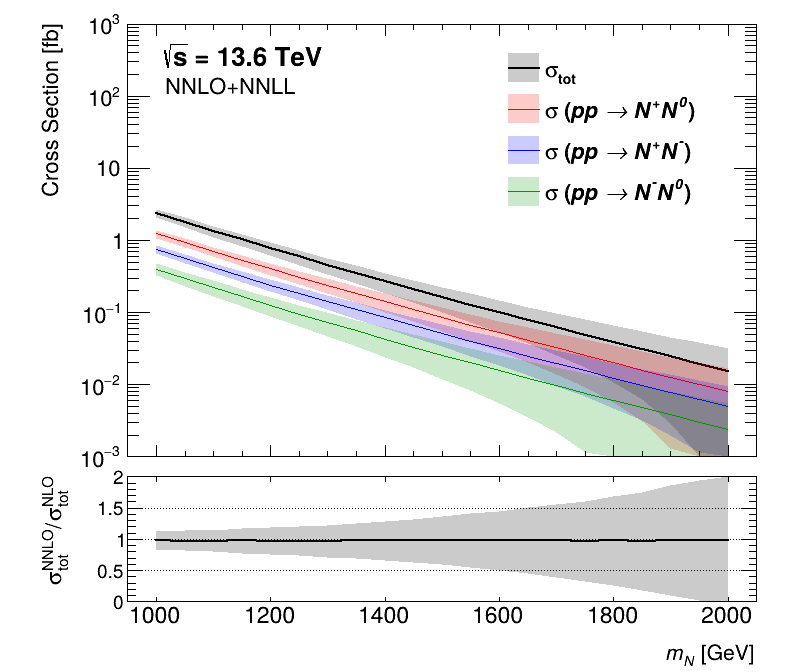

In [ ]:
res = get_results_from_df(df_13x6TeV_nnlo_nnll)
nlo_total = ROOT.TGraphAsymmErrors(res['n'], res['x'], res['y'], res['exl'], res['exh'], res['eyl'], res['eyh'])
nlo_total.SetName(f"nlo_total")
nlo_total.SetMarkerStyle(20)
nlo_total.SetLineWidth(2)
nlo_total.SetLineColor(ROOT.kBlack)
nlo_total.SetFillColorAlpha(ROOT.kBlack,0.2)
nlo_total.SetFillStyle(1001)

res = get_results("./cross_section/NLO/total/Events")
lo_total = ROOT.TGraphAsymmErrors(res['n'], res['x'], res['y'], res['exl'], res['exh'], res['eyl'], res['eyh'])
lo_total.SetName(f"nlo_total")
ratio_total = DivideTGraphAsymmErrors(nlo_total, lo_total)
ratio_total.SetMarkerStyle(20)
ratio_total.SetLineWidth(2)
ratio_total.SetLineColor(ROOT.kBlack)
ratio_total.SetFillColorAlpha(ROOT.kBlack,0.2)
ratio_total.SetFillStyle(1001)

#####################################
res = get_results_from_df(read_lhc_wdg("./cross_section/susy_nnlo_nnll_13x6TeV.csv", proc="sigp_sig0"))
nlo_sigp_sig0 = ROOT.TGraphAsymmErrors(res['n'], res['x'], res['y'], res['exl'], res['exh'], res['eyl'], res['eyh'])
nlo_sigp_sig0.SetName(f"nlo_sigp_sig0")
nlo_sigp_sig0.SetMarkerStyle(20)
nlo_sigp_sig0.SetLineColor(ROOT.kRed)
nlo_sigp_sig0.SetFillColorAlpha(ROOT.kRed,0.2)
nlo_sigp_sig0.SetFillStyle(1001)

#####################################
res = get_results_from_df(read_lhc_wdg("./cross_section/susy_nnlo_nnll_13x6TeV.csv", proc="sigp_sigm"))
nlo_sigp_sigm = ROOT.TGraphAsymmErrors(res['n'], res['x'], res['y'], res['exl'], res['exh'], res['eyl'], res['eyh'])
nlo_sigp_sigm.SetName(f"nlo_sigp_sigm")
nlo_sigp_sigm.SetMarkerStyle(20)
nlo_sigp_sigm.SetLineColor(ROOT.kBlue)
nlo_sigp_sigm.SetFillColorAlpha(ROOT.kBlue,0.2)
nlo_sigp_sigm.SetFillStyle(1001)

#####################################
res = get_results_from_df(read_lhc_wdg("./cross_section/susy_nnlo_nnll_13x6TeV.csv", proc="sigm_sig0"))
nlo_sigm_sig0 = ROOT.TGraphAsymmErrors(res['n'], res['x'], res['y'], res['exl'], res['exh'], res['eyl'], res['eyh'])
nlo_sigm_sig0.SetName(f"nlo_sigm_sig0")
nlo_sigm_sig0.SetMarkerStyle(20)
nlo_sigm_sig0.SetLineColor(ROOT.kGreen+2)
nlo_sigm_sig0.SetFillColorAlpha(ROOT.kGreen+2,0.2)
nlo_sigm_sig0.SetFillStyle(1001)

#####################################
multigraph_top = ROOT.TMultiGraph()
multigraph_top.SetName("multigraph_top")
multigraph_top.SetTitle("graph_top; #it{m_{N}} [GeV]; Cross Section [fb]")
multigraph_top.Add(nlo_total, "E3L")
multigraph_top.Add(nlo_sigp_sig0, "E3L")
multigraph_top.Add(nlo_sigp_sigm, "E3L")
multigraph_top.Add(nlo_sigm_sig0, "E3L")
multigraph_top.GetXaxis().SetLabelSize(0)
multigraph_top.GetXaxis().SetTitleSize(0)
multigraph_top.GetYaxis().SetTitleOffset(1.2)
multigraph_top.GetYaxis().SetRangeUser(1e-3, 1e3)

multigraph_down = ROOT.TMultiGraph()
multigraph_down.SetName("multigraph_down")
multigraph_down.SetTitle("graph_down; #it{m_{N}} [GeV]; #sigma^{NNLO}_{tot}/#sigma^{NLO}_{tot}")
multigraph_down.Add(ratio_total, "E3L")
multigraph_down.GetXaxis().SetLabelSize(0.125)
multigraph_down.GetXaxis().SetTitleSize(0.115)
multigraph_down.GetXaxis().SetNdivisions(10, ROOT.kTRUE)
multigraph_down.GetYaxis().SetLabelSize(0.10)
multigraph_down.GetYaxis().SetTitleSize(0.12)
multigraph_down.GetYaxis().SetTitleOffset(0.48)
multigraph_down.GetYaxis().SetRangeUser(0.0, 2.0)
multigraph_down.GetYaxis().SetNdivisions(505, True)

yI = 0.9
legend = ROOT.TLegend(0.63, yI-0.35, 0.85, yI)
legend.SetFillColor(0)
legend.SetBorderSize(0)
legend.SetTextSize(0.05)
legend.AddEntry(nlo_total, "#sigma_{tot}", 'lf')
legend.AddEntry(nlo_sigp_sig0, "#sigma (#it{pp #rightarrow N^{+}N^{0}})", 'lf')
legend.AddEntry(nlo_sigp_sigm, "#sigma (#it{pp #rightarrow N^{+}N^{-}})", 'lf')
legend.AddEntry(nlo_sigm_sig0, "#sigma (#it{pp #rightarrow N^{-}N^{0}})", 'lf')

label = ROOT.TLatex()
label.SetNDC()
label.SetTextSize(0.05)

canvas = ROOT.TCanvas("c", "c", 800, 700)
canvas.cd()
pad1 = ROOT.TPad("pad1", "pad1", 0.0, 0.30, 1.0, 1.0)
pad1.SetBottomMargin(0.03)                  
pad1.SetLogy(True)
pad1.Draw()
pad1.cd()
multigraph_top.Draw("ALP")
legend.Draw("same")
label.DrawLatex(0.20, 0.86, "#scale[1.2]{#bf{#sqrt{s} = %s TeV}}" % (13.6))
label.DrawLatex(0.20, 0.80, " NNLO+NNLL")
canvas.cd()
pad2 = ROOT.TPad("pad2", "pad2", 0.0, 0.0, 1.0, 0.30)
pad2.SetTopMargin(0.03)
pad2.SetBottomMargin(0.35)
pad2.SetGridy()
pad2.Draw()
pad2.cd()
multigraph_down.Draw("ALP") 
canvas.cd()
canvas.Update()
canvas.SaveAs(os.path.join(plots_dir, f"pair_production_cross_section.pdf"))
canvas.SaveAs(os.path.join(plots_dir, f"pair_production_cross_section.png"))
canvas.Close()
collect()
display(Image(filename=f"./plots/pair_production_cross_section.png"))

### Cross section plot using the NLO+PS and LO predictions

Info in <TCanvas::Print>: pdf file ./plots/pair_production_cross_section.pdf has been created


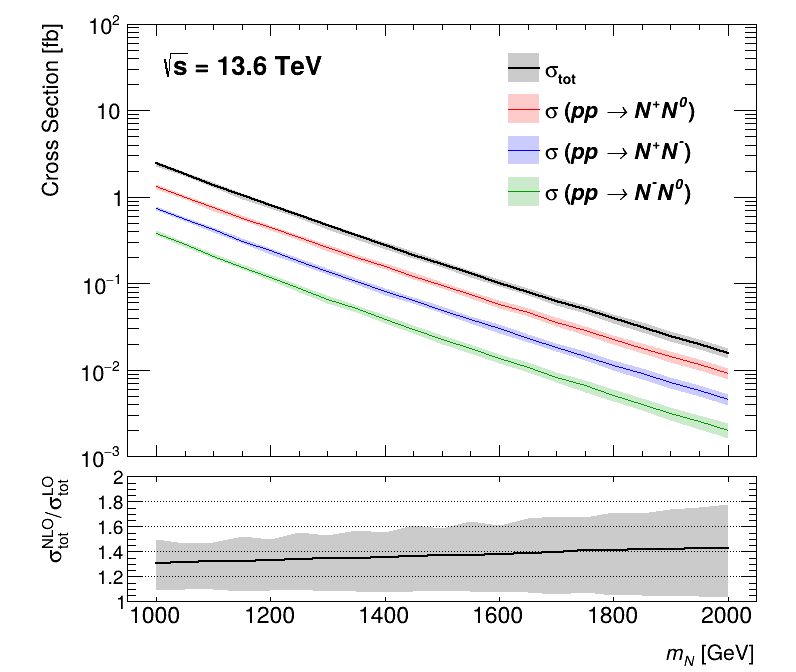

Info in <TCanvas::Print>: png file ./plots/pair_production_cross_section.png has been created


In [ ]:
res = get_results("./cross_section/NLO/total/Events")
nlo_total = ROOT.TGraphAsymmErrors(res['n'], res['x'], res['y'], res['exl'], res['exh'], res['eyl'], res['eyh'])
nlo_total.SetName(f"nlo_total")
nlo_total.SetMarkerStyle(20)
nlo_total.SetLineWidth(2)
nlo_total.SetLineColor(ROOT.kBlack)
nlo_total.SetFillColorAlpha(ROOT.kBlack,0.2)
nlo_total.SetFillStyle(1001)

res = get_results("./cross_section/LO/total/Events")
lo_total = ROOT.TGraphAsymmErrors(res['n'], res['x'], res['y'], res['exl'], res['exh'], res['eyl'], res['eyh'])
lo_total.SetName(f"nlo_total")
ratio_total = DivideTGraphAsymmErrors(nlo_total, lo_total)
ratio_total.SetMarkerStyle(20)
ratio_total.SetLineWidth(2)
ratio_total.SetLineColor(ROOT.kBlack)
ratio_total.SetFillColorAlpha(ROOT.kBlack,0.2)
ratio_total.SetFillStyle(1001)

#####################################
res = get_results("./cross_section/NLO/sigp_sig0/Events")
nlo_sigp_sig0 = ROOT.TGraphAsymmErrors(res['n'], res['x'], res['y'], res['exl'], res['exh'], res['eyl'], res['eyh'])
nlo_sigp_sig0.SetName(f"nlo_sigp_sig0")
nlo_sigp_sig0.SetMarkerStyle(20)
nlo_sigp_sig0.SetLineColor(ROOT.kRed)
nlo_sigp_sig0.SetFillColorAlpha(ROOT.kRed,0.2)
nlo_sigp_sig0.SetFillStyle(1001)

#####################################
res = get_results("./cross_section/NLO/sigp_sigm/Events")
nlo_sigp_sigm = ROOT.TGraphAsymmErrors(res['n'], res['x'], res['y'], res['exl'], res['exh'], res['eyl'], res['eyh'])
nlo_sigp_sigm.SetName(f"nlo_sigp_sigm")
nlo_sigp_sigm.SetMarkerStyle(20)
nlo_sigp_sigm.SetLineColor(ROOT.kBlue)
nlo_sigp_sigm.SetFillColorAlpha(ROOT.kBlue,0.2)
nlo_sigp_sigm.SetFillStyle(1001)

#####################################
res = get_results("./cross_section/NLO/sigm_sig0/Events")
nlo_sigm_sig0 = ROOT.TGraphAsymmErrors(res['n'], res['x'], res['y'], res['exl'], res['exh'], res['eyl'], res['eyh'])
nlo_sigm_sig0.SetName(f"nlo_sigm_sig0")
nlo_sigm_sig0.SetMarkerStyle(20)
nlo_sigm_sig0.SetLineColor(ROOT.kGreen+2)
nlo_sigm_sig0.SetFillColorAlpha(ROOT.kGreen+2,0.2)
nlo_sigm_sig0.SetFillStyle(1001)

#####################################
multigraph_top = ROOT.TMultiGraph()
multigraph_top.SetName("multigraph_top")
multigraph_top.SetTitle("graph_top; #it{m_{N}} [GeV]; Cross Section [fb]")
multigraph_top.Add(nlo_total, "E3L")
multigraph_top.Add(nlo_sigp_sig0, "E3L")
multigraph_top.Add(nlo_sigp_sigm, "E3L")
multigraph_top.Add(nlo_sigm_sig0, "E3L")
multigraph_top.GetXaxis().SetLabelSize(0)
multigraph_top.GetXaxis().SetTitleSize(0)
multigraph_top.GetYaxis().SetTitleOffset(1.2)
multigraph_top.GetYaxis().SetRangeUser(1e-3, 1e2)

multigraph_down = ROOT.TMultiGraph()
multigraph_down.SetName("multigraph_down")
multigraph_down.SetTitle("graph_down; #it{m_{N}} [GeV]; #sigma^{NLO}_{tot}/#sigma^{LO}_{tot}")
multigraph_down.Add(ratio_total, "E3L")
multigraph_down.GetXaxis().SetLabelSize(0.125)
multigraph_down.GetXaxis().SetTitleSize(0.115)
multigraph_down.GetXaxis().SetNdivisions(10, ROOT.kTRUE)
multigraph_down.GetYaxis().SetLabelSize(0.10)
multigraph_down.GetYaxis().SetTitleSize(0.12)
multigraph_down.GetYaxis().SetTitleOffset(0.48)
multigraph_down.GetYaxis().SetRangeUser(1.0, 2.0)
multigraph_down.GetYaxis().SetNdivisions(505, True)

yI = 0.9
legend = ROOT.TLegend(0.63, yI-0.35, 0.85, yI)
legend.SetFillColor(0)
legend.SetBorderSize(0)
legend.SetTextSize(0.05)
legend.AddEntry(nlo_total, "#sigma_{tot}", 'lf')
legend.AddEntry(nlo_sigp_sig0, "#sigma (#it{pp #rightarrow N^{+}N^{0}})", 'lf')
legend.AddEntry(nlo_sigp_sigm, "#sigma (#it{pp #rightarrow N^{+}N^{-}})", 'lf')
legend.AddEntry(nlo_sigm_sig0, "#sigma (#it{pp #rightarrow N^{-}N^{0}})", 'lf')

label = ROOT.TLatex()
label.SetNDC()
label.SetTextSize(0.05)

canvas = ROOT.TCanvas("c", "c", 800, 700)
canvas.cd()
pad1 = ROOT.TPad("pad1", "pad1", 0.0, 0.30, 1.0, 1.0)
pad1.SetBottomMargin(0.03)                  
pad1.SetLogy(True)
pad1.Draw()
pad1.cd()
multigraph_top.Draw("ALP")
legend.Draw("same")
label.DrawLatex(0.20, 0.84, "#scale[1.2]{#bf{#sqrt{s} = %s TeV}}" % (13.6))

canvas.cd()
pad2 = ROOT.TPad("pad2", "pad2", 0.0, 0.0, 1.0, 0.30)
pad2.SetTopMargin(0.03)
pad2.SetBottomMargin(0.35)
pad2.SetGridy()
pad2.Draw()
pad2.cd()
multigraph_down.Draw("ALP") 
canvas.cd()
canvas.Update()
canvas.SaveAs(os.path.join(plots_dir, f"pair_production_cross_section.pdf"))
canvas.SaveAs(os.path.join(plots_dir, f"pair_production_cross_section.png"))
canvas.Close()
collect()
display(Image(filename=f"./plots/pair_production_cross_section.png"))

## Total Decay Width and the Branching Ratios

For the method below to work, you should print out all the run results, this can be done via the following MadGraph5 options:

- launch ./sig0_all_all -i
- print_results --format=short --path=./sig0_all_all/results_short.txt --mode=w
- print_results --format=full --path=./sig0_all_all/results_full.txt --mode=w

The produced .txt files need to be read in csv format in order to processed

In [10]:
def get_csv_file(base_dir):
    results_short_txt = os.path.join(base_dir, 'results_short.txt')
    df = pd.read_csv(results_short_txt,  sep='\s+', comment='#', names=['run_name', 'tag', 'cross', 'error', 'Nb_event', 'cross_after_matching', 'nb_event_after_matching'])
    return df

<>:3: SyntaxWarning: invalid escape sequence '\s'
<>:3: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_1694/3110827962.py:3: SyntaxWarning: invalid escape sequence '\s'
  df = pd.read_csv(results_short_txt,  sep='\s+', comment='#', names=['run_name', 'tag', 'cross', 'error', 'Nb_event', 'cross_after_matching', 'nb_event_after_matching'])


In [11]:
data_dir = '/mnt/e/1WORK/neutrino/typeIIIseesaw/kinematics/decays/fdm/'

def get_branching_ratio(inclusive_dir, exclusive_dir):
    df_inc = get_csv_file(os.path.join(data_dir,inclusive_dir))
    df_exc = get_csv_file(os.path.join(data_dir,exclusive_dir))
    x, y, w = [],  [],  []
    for mass in ([125] + list(range(100, 2000+50, 50))):
        x.append(mass)
        width = df_inc.loc[df_inc['run_name'] == f'M{mass}', 'cross'].item()
        try:
            br = df_exc.loc[df_exc['run_name'] == f'M{mass}', 'cross'].item() / width
        except Exception as e:
            br = 0.0
        y.append(br)
        w.append(width)

    n = len(x)
    return {
        'n': n,
        'x' : np.array(x, dtype='double'), 
        'y' : np.array(y, dtype='double'),
        'w' : np.array(w, dtype='double')
    }

Theoritical predictions

In [12]:
aEWM1 = 127.9
MZ = 91.1876
MH = 125.0
Gf = 1.16637e-05
MW = ((MZ**2/2) + ((MZ**4/4) - ((1/aEWM1)*np.pi*MZ**2)/(Gf*np.sqrt(2)))**0.5)**0.5
cW = MW/MZ
g = (4 * 3.141592653589793 / aEWM1)**0.5 / ((1-cW**2)**0.5) 
m_pi = 0.13957         # Pion mass m_pi (in GeV)
f_pi = 0.13           # Pion decay constant f_pi (in GeV)
V_ud = 0.97420          # CKM matrix element V_ud

In [13]:
def typeIII_HeavyStateTransition_widths(M):

    def f(r):
        """Loop function f(r). r is a scalar (float). Returns real float."""
        rc = complex(r)
        sqrt_term = cmath.sqrt(rc*rc - 4.0)
        A = (rc*rc - 2.0 - rc * sqrt_term) / 2.0
        lnA = cmath.log(A)
        val = (rc / 2.0) * (2.0 * rc**3 * cmath.log(rc) - 2.0 * rc + sqrt_term * (rc**2 + 2.0) * lnA)
        return float(val.real)

    def DeltaM(M):
        M = float(M)
        return float(((g * g * M) / (16.0 * np.pi * np.pi)) * (f(MW / M) - (cW**2) * f(MZ / M)))

    Gamma_sigm_sig0_pi = (2.0 / np.pi) * (Gf**2) * (V_ud**2) * (DeltaM(M)**3) * (f_pi**2) * np.sqrt(np.maximum(0.0, 1.0 - (m_pi**2) / (DeltaM(M)**2)))
    Gamma_sigm_sig0_e_ve = (2.0 / (15.0 * np.pi)) * (Gf**2) * (DeltaM(M)**5)
    Gamma_sigm_sig0_mu_vm = 0.12 * Gamma_sigm_sig0_e_ve
    Gamma_sigm_sig0_l_vl = Gamma_sigm_sig0_e_ve + Gamma_sigm_sig0_mu_vm

    return {
        "Delta_M_MeV": DeltaM(M) * 1000,
        "Gamma_sigm_sig0_pi": Gamma_sigm_sig0_pi,
        "Gamma_sigm_sig0_e_ve": Gamma_sigm_sig0_e_ve,
        "Gamma_sigm_sig0_mu_vm": Gamma_sigm_sig0_mu_vm,
        "Gamma_sigm_sig0_l_vl" : Gamma_sigm_sig0_l_vl,
        "width_sigm": Gamma_sigm_sig0_pi + Gamma_sigm_sig0_l_vl
    }

def typeIII_TwoBodyDecay_widths(M,V):
    """
    Compute decay widths of Type III seessaw heavy triplets.
    """
    def f1(M, MX):
        return ( g**2 / (64 * np.pi) ) *  ( M**3 / MX**2 ) * ( (1 - ( MX**2 / M**2 ) ) **2 ) * ( 1 + 2 * (MX**2 / M**2) ) if M > MX else 0

    def f2(M, MX):
        return ( g**2 / (64 * np.pi) ) * ( M**3 / MW**2 ) * ( (1 - ( MX**2 / M**2 ) ) **2 ) if M > MX else 0

    # Sigma0 decays
    Gamma_sig0_wpm_lpm =  np.sum(V**2) * f1(M, MW)
    Gamma_sig0_z_vl =  cW**(-2) * np.sum(V**2) * f1(M, MZ)
    Gamma_sig0_h_vl = np.sum(V**2) * f2(M, MH)

    # Sigma- decays
    Gamma_sigm_wm_vl = 2 * np.sum(V**2) * f1(M, MW)
    Gamma_sigm_z_l =  cW**(-2) * np.sum(V**2) * f1(M, MZ)
    Gamma_sigm_h_l= np.sum(V**2) * f2(M, MH)

    return {
        "Gamma_sig0_wpm_lmp": Gamma_sig0_wpm_lpm * 2,
        "Gamma_sig0_z_vl": Gamma_sig0_z_vl,
        "Gamma_sig0_h_vl": Gamma_sig0_h_vl,
        "width_sig0": Gamma_sig0_wpm_lpm * 2 + Gamma_sig0_z_vl + Gamma_sig0_h_vl,
        "Gamma_sigm_wm_vl": Gamma_sigm_wm_vl,
        "Gamma_sigm_z_l": Gamma_sigm_z_l,
        "Gamma_sigm_h_l": Gamma_sigm_h_l,
        "width_sigm": Gamma_sigm_wm_vl + Gamma_sigm_z_l + Gamma_sigm_h_l
    }

def typeIII_br(M,V):
    width_sig0 = typeIII_TwoBodyDecay_widths(M,V)["width_sig0"] 
    width_sigm = typeIII_TwoBodyDecay_widths(M,V)["width_sigm"] + typeIII_HeavyStateTransition_widths(M)["width_sigm"]
    return {
        "width_sig0" : width_sig0,
        "width_sigm" : width_sigm,
        "br_sig0_wpm_lmp": typeIII_TwoBodyDecay_widths(M,V)["Gamma_sig0_wpm_lmp"] / width_sig0,
        "br_sig0_z_vl": typeIII_TwoBodyDecay_widths(M,V)["Gamma_sig0_z_vl"] / width_sig0,
        "br_sig0_h_vl": typeIII_TwoBodyDecay_widths(M,V)["Gamma_sig0_h_vl"] / width_sig0,
        "br_sigm_wm_vl": typeIII_TwoBodyDecay_widths(M,V)["Gamma_sigm_wm_vl"] / width_sigm,
        "br_sigm_z_l": typeIII_TwoBodyDecay_widths(M,V)["Gamma_sigm_z_l"] / width_sigm,
        "br_sigm_h_l": typeIII_TwoBodyDecay_widths(M,V)["Gamma_sigm_h_l"] / width_sigm,
        "br_sigm_sig0_pi": typeIII_HeavyStateTransition_widths(M)["Gamma_sigm_sig0_pi"] / width_sigm,
        "br_sigm_sig0_e_ve": typeIII_HeavyStateTransition_widths(M)["Gamma_sigm_sig0_e_ve"] / width_sigm,
        "br_sigm_sig0_mu_vm": typeIII_HeavyStateTransition_widths(M)["Gamma_sigm_sig0_mu_vm"] / width_sigm,
        "br_sigm_sig0_l_vl": typeIII_HeavyStateTransition_widths(M)["Gamma_sigm_sig0_l_vl"] / width_sigm,
    }

Prepare the csv table

In [14]:
df_br = pd.DataFrame()
df_br["mass"] = get_branching_ratio('sigm_all_all', 'sigm_wm_vl')["x"]
df_br["br_sigm_wm_vl"] = get_branching_ratio('sigm_all_all', 'sigm_wm_vl')["y"]
df_br["br_sigm_z_lm"] = get_branching_ratio('sigm_all_all', 'sigm_z_lm')["y"]
df_br["br_sigm_h_lm"] = get_branching_ratio('sigm_all_all', 'sigm_h_lm')["y"]
df_br["br_sig0_wpm_lpm"] = get_branching_ratio('sig0_all_all', 'sig0_wpm_lpm')["y"]
df_br["br_sig0_z_vl"] = get_branching_ratio('sig0_all_all', 'sig0_z_vl')["y"]
df_br["br_sig0_h_vl"] = get_branching_ratio('sig0_all_all', 'sig0_h_vl')["y"]
df_br["w_sigm"] = get_branching_ratio('sigm_all_all', 'sigm_h_lm')["w"]
df_br["w_sig0"] = get_branching_ratio('sig0_all_all', 'sig0_h_vl')["w"]
display(df_br)
df_br.to_csv(os.path.join(tables_dir, "branching_ratios.csv"), index=False)

# df_br_latex = pd.DataFrame()
# df_br_latex["mass"] = df_br["mass"].astype(int)
# df_br_latex["br_sigm_wm_vl [%]"] = df_br.apply(lambda r: f"{r.br_sigm_wm_vl * 100:.2f}%", axis=1)
# df_br_latex["br_sigm_z_lm [%]"] = df_br.apply(lambda r: f"{r.br_sigm_z_lm * 100:.2f}%", axis=1)
# df_br_latex["br_sigm_h_lm [%]"] = df_br.apply(lambda r: f"{r.br_sigm_h_lm * 100:.2f}%", axis=1)
# print(df_br_latex.to_latex(index=False, escape=False))

,mass,br_sigm_wm_vl,br_sigm_z_lm,br_sigm_h_lm,br_sig0_wpm_lpm,br_sig0_z_vl,br_sig0_h_vl,w_sigm,w_sig0
0,125.0,0.738357,0.261642,0.000000,0.737965,0.262012,0.000000,3.322167e-08,3.321555e-08
1,100.0,0.890201,0.109752,0.000000,0.887275,0.112720,0.000000,8.697253e-04,8.671746e-04
2,150.0,0.672414,0.288631,0.039007,0.672225,0.288762,0.039004,7.967900e-08,7.967748e-08
3,200.0,0.596738,0.284376,0.118903,0.596731,0.284403,0.118890,2.464446e-07,2.464345e-07
4,250.0,0.561870,0.275324,0.162782,0.561838,0.275352,0.162761,5.325770e-07,5.325543e-07
5,300.0,0.543038,0.268844,0.188138,0.543034,0.268852,0.188125,9.666720e-07,9.666692e-07
6,350.0,0.531620,0.264372,0.203940,0.531661,0.264388,0.203943,1.578307e-06,1.578223e-06
7,400.0,0.524314,0.261332,0.214460,0.524256,0.261286,0.214426,2.396488e-06,2.396747e-06
8,450.0,0.519194,0.259068,0.221726,0.519162,0.259067,0.221717,3.451916e-06,3.451948e-06
9,500.0,0.515564,0.257438,0.227021,0.515562,0.257439,0.227003,4.773219e-06,4.773157e-06


Make the plots

Info in <TCanvas::Print>: pdf file ./plots/br_sigm.pdf has been created
Info in <TCanvas::Print>: png file ./plots/br_sigm.png has been created


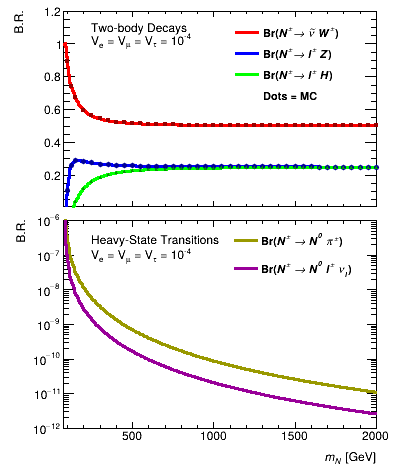

In [15]:
sa = 5 
V = np.array([1e-4, 1e-4, 1e-4])

res = get_branching_ratio('sigm_all_all', 'sigm_wm_vl')
br_sigm_wm_vl = ROOT.TGraph(res['n'], res['x'], res['y'])
br_sigm_wm_vl.SetName(f"br_sigm_wm_vl")
br_sigm_wm_vl.SetMarkerColor(ROOT.kRed + 2)
br_sigm_wm_vl.SetMarkerSize(0.5)
br_sigm_wm_vl.SetMarkerStyle(21)
th_res = np.array([(m, typeIII_br(m,V)['br_sigm_wm_vl']) for m in range(80, 2000+sa, sa)], dtype='float')
th_br_sigm_wm_vl = ROOT.TGraph(th_res.shape[0], th_res[:, 0].astype('double'), th_res[:, 1].astype('double'))
th_br_sigm_wm_vl.SetLineColor(ROOT.kRed)
th_br_sigm_wm_vl.SetLineWidth(3)

res = get_branching_ratio('sigm_all_all', 'sigm_z_lm')
br_sigm_z_lm = ROOT.TGraph(res['n'], res['x'], res['y'])
br_sigm_z_lm.SetName(f"br_sigm_z_lm")
br_sigm_z_lm.SetMarkerColor(ROOT.kBlue + 2)
br_sigm_z_lm.SetMarkerSize(0.5)
br_sigm_z_lm.SetMarkerStyle(20)
th_res = np.array([(m, typeIII_br(m,V)['br_sigm_z_l']) for m in range(80, 2000+sa, sa)], dtype='float')
th_br_sigm_z_lm = ROOT.TGraph(th_res.shape[0], th_res[:, 0].astype('double'), th_res[:, 1].astype('double'))
th_br_sigm_z_lm.SetLineColor(ROOT.kBlue)
th_br_sigm_z_lm.SetLineWidth(3)

res = get_branching_ratio('sigm_all_all', 'sigm_h_lm')
br_sigm_h_lm = ROOT.TGraph(res['n'], res['x'], res['y'])
br_sigm_h_lm.SetName(f"br_sigm_h_lm")
br_sigm_h_lm.SetMarkerColor(ROOT.kGreen + 2)
br_sigm_h_lm.SetMarkerSize(0.5)
br_sigm_h_lm.SetMarkerStyle(22)
th_res = np.array([(m, typeIII_br(m,V)['br_sigm_h_l']) for m in range(80, 2000+sa, sa)], dtype='float')
th_br_sigm_h_lm = ROOT.TGraph(th_res.shape[0], th_res[:, 0].astype('double'), th_res[:, 1].astype('double'))
th_br_sigm_h_lm.SetLineColor(ROOT.kGreen)
th_br_sigm_h_lm.SetLineWidth(3)

th_res = np.array([(m, typeIII_br(m,V)['br_sigm_sig0_pi']) for m in range(80, 2000+sa, sa)], dtype='float')
th_br_sigm_sig0_pi = ROOT.TGraph(th_res.shape[0], th_res[:, 0].astype('double'), th_res[:, 1].astype('double'))
th_br_sigm_sig0_pi.SetLineColor(ROOT.kYellow + 2)
th_br_sigm_sig0_pi.SetLineWidth(3)

th_res = np.array([(m, typeIII_br(m,V)['br_sigm_sig0_l_vl']) for m in range(80, 2000+sa, sa)], dtype='float')
th_br_sigm_sig0_l_vl = ROOT.TGraph(th_res.shape[0], th_res[:, 0].astype('double'), th_res[:, 1].astype('double'))
th_br_sigm_sig0_l_vl.SetLineColor(ROOT.kMagenta + 2)
th_br_sigm_sig0_l_vl.SetLineWidth(3)

multigraph1_sigm = ROOT.TMultiGraph()
multigraph1_sigm.SetName("multigraph1_sigm")
multigraph1_sigm.SetTitle("multigraph1_sigm; #it{m_{N}} [GeV]; B.R.")
multigraph1_sigm.Add(th_br_sigm_wm_vl, "l")
multigraph1_sigm.Add(th_br_sigm_z_lm, "l")
multigraph1_sigm.Add(th_br_sigm_h_lm, "l")
multigraph1_sigm.Add(br_sigm_wm_vl, "p")
multigraph1_sigm.Add(br_sigm_z_lm, "p")
multigraph1_sigm.Add(br_sigm_h_lm, "p")
multigraph1_sigm.GetYaxis().SetLabelSize(0.06)
multigraph1_sigm.GetYaxis().SetTitleSize(0.06)
multigraph1_sigm.GetXaxis().SetLabelSize(0)
multigraph1_sigm.GetXaxis().SetTitleSize(0)
multigraph1_sigm.GetYaxis().SetTitleOffset(1.2)
multigraph1_sigm.GetXaxis().SetRangeUser(80, 2000)
multigraph1_sigm.GetXaxis().SetNdivisions(505, ROOT.kTRUE)
multigraph1_sigm.GetYaxis().SetRangeUser(0.01, 1.2)
multigraph1_sigm.GetYaxis().SetNdivisions(808, ROOT.kTRUE)

multigraph2_sigm = ROOT.TMultiGraph()
multigraph2_sigm.SetName("multigraph2_sigm")
multigraph2_sigm.SetTitle("multigraph2_sigm; #it{m_{N}} [GeV]; B.R.")
multigraph2_sigm.Add(th_br_sigm_sig0_pi, "l")
multigraph2_sigm.Add(th_br_sigm_sig0_l_vl, "l")
multigraph2_sigm.GetXaxis().SetRangeUser(80, 2000)
multigraph2_sigm.GetXaxis().SetNdivisions(505, ROOT.kTRUE)
multigraph2_sigm.GetYaxis().SetRangeUser(1e-12, 1e-6)
multigraph2_sigm.GetYaxis().SetNdivisions(505, ROOT.kTRUE)

yI = 0.9
legend1 = ROOT.TLegend(0.58, yI-0.4, 0.92, yI)
legend1.SetFillColor(0)
legend1.SetBorderSize(0)
legend1.SetTextSize(0.055)
legend1.AddEntry(th_br_sigm_wm_vl, "Br(#it{N^{#pm}#rightarrow #tilde{#nu} W^{#pm}})","l")
legend1.AddEntry(th_br_sigm_z_lm, "Br(#it{N^{#pm}#rightarrow l^{#pm} Z})","l")
legend1.AddEntry(th_br_sigm_h_lm, "Br(#it{N^{#pm}#rightarrow l^{#pm} H})","l")
legend1.AddEntry(0, "Dots = MC", "")

yI = 0.95
legend2 = ROOT.TLegend(0.58, yI-0.22, 0.9, yI)
legend2.SetFillColor(0)
legend2.SetBorderSize(0)
legend2.SetTextSize(0.045)
legend2.AddEntry(th_br_sigm_sig0_pi, "Br(#it{N^{#pm} #rightarrow N^{0} #pi^{#pm}})","l")
legend2.AddEntry(th_br_sigm_sig0_l_vl, "Br(#it{N^{#pm} #rightarrow N^{0} l^{#pm} #nu_{l}})","l")

label = ROOT.TLatex()
label.SetNDC()
label.SetTextSize(0.06)

canvas = ROOT.TCanvas("c", "c", 400, 500)
canvas.cd()
pad1 = ROOT.TPad("pad1", "pad1", 0.0, 0.55, 1.0, 1.0)
pad1.SetBottomMargin(0.03)       
pad1.SetLogy(False)
pad1.SetGridy(False)           
pad1.Draw()
pad1.cd()
multigraph1_sigm.Draw("ALP")
legend1.Draw("same")
label.SetTextSize(0.06)
label.DrawLatex(0.23, 0.85, "Two-body Decays")
label.DrawLatex(0.23, 0.79, "V_{e} = V_{#mu} = V_{#tau} = 10^{-4}")
canvas.cd()
pad2 = ROOT.TPad("pad2", "pad2", 0.0, 0.0, 1.0, 0.55)
pad2.SetTopMargin(0.03)
pad2.SetBottomMargin(0.17)
pad2.SetLogy(True)
pad2.SetGridy(False)
pad2.Draw()
pad2.cd()
multigraph2_sigm.Draw("ALP")
legend2.Draw("same")
label.SetTextSize(0.05)
label.DrawLatex(0.23, 0.88, "Heavy-State Transitions")
label.DrawLatex(0.23, 0.82, "V_{e} = V_{#mu} = V_{#tau} = 10^{-4}")
canvas.Update()
canvas.SaveAs(os.path.join(plots_dir, f"br_sigm.pdf"))
canvas.SaveAs(os.path.join(plots_dir, f"br_sigm.png"))
canvas.Close()
collect()
display(Image(filename=f"./plots/br_sigm.png"))

Info in <TCanvas::Print>: pdf file ./plots/br_sigm_two_body.pdf has been created


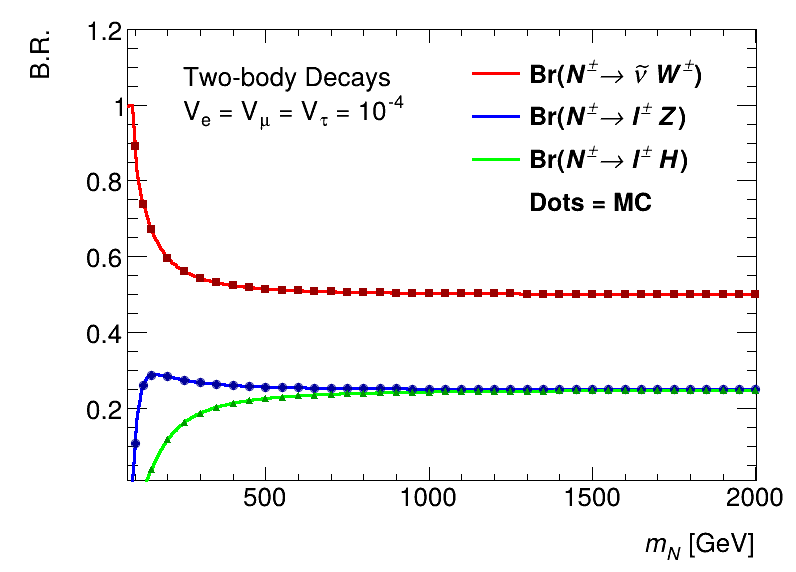

Info in <TCanvas::Print>: png file ./plots/br_sigm_two_body.png has been created


In [16]:
sa = 5 
V = np.array([1e-4, 1e-4, 1e-4])

res = get_branching_ratio('sigm_all_all', 'sigm_wm_vl')
br_sigm_wm_vl = ROOT.TGraph(res['n'], res['x'], res['y'])
br_sigm_wm_vl.SetName(f"br_sigm_wm_vl")
br_sigm_wm_vl.SetMarkerColor(ROOT.kRed + 2)
br_sigm_wm_vl.SetMarkerSize(1.0)
br_sigm_wm_vl.SetMarkerStyle(21)
th_res = np.array([(m, typeIII_br(m,V)['br_sigm_wm_vl']) for m in range(80, 2000+sa, sa)], dtype='float')
th_br_sigm_wm_vl = ROOT.TGraph(th_res.shape[0], th_res[:, 0].astype('double'), th_res[:, 1].astype('double'))
th_br_sigm_wm_vl.SetLineColor(ROOT.kRed)
th_br_sigm_wm_vl.SetLineWidth(3)

res = get_branching_ratio('sigm_all_all', 'sigm_z_lm')
br_sigm_z_lm = ROOT.TGraph(res['n'], res['x'], res['y'])
br_sigm_z_lm.SetName(f"br_sigm_z_lm")
br_sigm_z_lm.SetMarkerColor(ROOT.kBlue + 2)
br_sigm_z_lm.SetMarkerSize(1.0)
br_sigm_z_lm.SetMarkerStyle(20)
th_res = np.array([(m, typeIII_br(m,V)['br_sigm_z_l']) for m in range(80, 2000+sa, sa)], dtype='float')
th_br_sigm_z_lm = ROOT.TGraph(th_res.shape[0], th_res[:, 0].astype('double'), th_res[:, 1].astype('double'))
th_br_sigm_z_lm.SetLineColor(ROOT.kBlue)
th_br_sigm_z_lm.SetLineWidth(3)

res = get_branching_ratio('sigm_all_all', 'sigm_h_lm')
br_sigm_h_lm = ROOT.TGraph(res['n'], res['x'], res['y'])
br_sigm_h_lm.SetName(f"br_sigm_h_lm")
br_sigm_h_lm.SetMarkerColor(ROOT.kGreen + 2)
br_sigm_h_lm.SetMarkerSize(1.0)
br_sigm_h_lm.SetMarkerStyle(22)
th_res = np.array([(m, typeIII_br(m,V)['br_sigm_h_l']) for m in range(80, 2000+sa, sa)], dtype='float')
th_br_sigm_h_lm = ROOT.TGraph(th_res.shape[0], th_res[:, 0].astype('double'), th_res[:, 1].astype('double'))
th_br_sigm_h_lm.SetLineColor(ROOT.kGreen)
th_br_sigm_h_lm.SetLineWidth(3)

multigraph1_sigm = ROOT.TMultiGraph()
multigraph1_sigm.SetName("multigraph1_sigm")
multigraph1_sigm.SetTitle("multigraph1_sigm; #it{m_{N}} [GeV]; B.R.")
multigraph1_sigm.Add(th_br_sigm_wm_vl, "l")
multigraph1_sigm.Add(th_br_sigm_z_lm, "l")
multigraph1_sigm.Add(th_br_sigm_h_lm, "l")
multigraph1_sigm.Add(br_sigm_wm_vl, "p")
multigraph1_sigm.Add(br_sigm_z_lm, "p")
multigraph1_sigm.Add(br_sigm_h_lm, "p")
multigraph1_sigm.GetXaxis().SetRangeUser(80, 2000)
multigraph1_sigm.GetXaxis().SetNdivisions(505, ROOT.kTRUE)
multigraph1_sigm.GetYaxis().SetRangeUser(0.01, 1.2)
multigraph1_sigm.GetYaxis().SetNdivisions(808, ROOT.kTRUE)

yI = 0.91
legend1 = ROOT.TLegend(0.58, yI-0.3, 0.92, yI)
legend1.SetFillColor(0)
legend1.SetBorderSize(0)
legend1.SetTextSize(0.048)
legend1.AddEntry(th_br_sigm_wm_vl, "Br(#it{N^{#pm}#rightarrow #tilde{#nu} W^{#pm}})","l")
legend1.AddEntry(th_br_sigm_z_lm, "Br(#it{N^{#pm}#rightarrow l^{#pm} Z})","l")
legend1.AddEntry(th_br_sigm_h_lm, "Br(#it{N^{#pm}#rightarrow l^{#pm} H})","l")
legend1.AddEntry(0, "Dots = MC", "")

label = ROOT.TLatex()
label.SetNDC()

canvas = ROOT.TCanvas("c", "c", 800, 600)
multigraph1_sigm.Draw("ALP")
legend1.Draw("same")
label.SetTextSize(0.05)
label.DrawLatex(0.23, 0.85, "Two-body Decays")
label.DrawLatex(0.23, 0.79, "V_{e} = V_{#mu} = V_{#tau} = 10^{-4}")
canvas.Update()
canvas.SaveAs(os.path.join(plots_dir, f"br_sigm_two_body.pdf"))
canvas.SaveAs(os.path.join(plots_dir, f"br_sigm_two_body.png"))
canvas.Close()
collect()
display(Image(filename=f"./plots/br_sigm_two_body.png"))

## Collider Signatures

Here we wish to explore the collider signatures arising from all 27 distinct leading order (LO) production and decay processes resulting from the decays of each of $N^+N^0$, $N^+N^-$ and $N^-N^0$ pairs into nine different pairs of $W^\pm$, $Z$ and $H$ bosons. Since the neutral component $N^0$ is a Majorana neutrino, both the $N^0\to \ell^+ W^-$ and $N^0\to \ell^- W^+$ channels are included with equal rates.

In [17]:
# W+ decays
w_lnu   = 0.1086 * 2  # e+ve + mu+vm (21.34%)
w_taunu = 0.1138      # tau+vt
w_had   = 0.6741      # qq'

# Z decays
z_ll     = 0.03363 * 2 # e+e- + mu+mu- (6.73%)
z_tautau = 0.0337
z_nunu   = 0.2000
z_had    = 0.6991

# Higgs (125 GeV) decays
h_had    = 0.6931      # bb, gg, cc
h_ww     = 0.2137
h_zz     = 0.0264
h_tautau = 0.0627
h_mumu   = 0.0002

# Tau decay fractions
tau_lnu = 0.3521       # tau -> e/mu + neutrinos
tau_had = 0.6479       # tau -> hadrons + neutrino

Or we can read directly from Pythia8

In [21]:
sys.path.append("/home/ammelsayed/softwares/pythia8318/lib")
import pythia8

def get_br(pythia, parent_id, daughters):
    """Return the Pythia branching ratio for a specific decay channel."""
    particle = pythia.particleData.particleDataEntryPtr(parent_id)
    daughters = tuple(daughters)

    for i in range(particle.sizeChannels()):
        ch = particle.channel(i)

        if not ch.onMode():
            continue

        products = tuple(
            ch.product(j)
            for j in range(ch.multiplicity())
        )

        if products == daughters:
            return ch.bRatio()

    raise ValueError(
        f"Decay channel {parent_id} -> {daughters} not found"
    )


pythia = pythia8.Pythia()
pythia.init()

# W+ 
W_lnu = get_br(pythia, 24, [-11, 12]) + get_br(pythia, 24, [-13, 14])
W_taunu = get_br(pythia, 24, [-15, 16])
W_had = 1.0 - W_lnu - W_taunu

# Z 
Z_ll = get_br(pythia, 23, [11, -11]) + get_br(pythia, 23, [13, -13])
Z_tautau = get_br(pythia, 23, [15, -15])
Z_nunu = get_br(pythia, 23, [12, -12]) + get_br(pythia, 23, [14, -14]) + get_br(pythia, 23, [16, -16])
Z_had = 1.0 - Z_ll - Z_tautau - Z_nunu

# Higgs branching ratios
H_WW = get_br(pythia, 25, [24, -24])
H_ZZ = get_br(pythia, 25, [23, 23])
H_tautau = get_br(pythia, 25, [15, -15])
H_mumu = get_br(pythia, 25, [13, -13])
H_had = 1.0 - H_WW - H_ZZ - H_tautau - H_mumu

# Tau branching ratios
tau_lnu = get_br(pythia, 15, [16, 11, -12]) + get_br(pythia, 15, [16, 13, -14])
tau_had = 1.0 - tau_lnu


 *------------------------------------------------------------------------------------* 
 |                                                                                    | 
 |  *------------------------------------------------------------------------------*  | 
 |  |                                                                              |  | 
 |  |                                                                              |  | 
 |  |   PPP   Y   Y  TTTTT  H   H  III    A      Welcome to the Lund Monte Carlo!  |  | 
 |  |   P  P   Y Y     T    H   H   I    A A     This is PYTHIA version 8.318      |  | 
 |  |   PPP     Y      T    HHHHH   I   AAAAA    Last date of change: 16 Sep 2026  |  | 
 |  |   P       Y      T    H   H   I   A   A                                      |  | 
 |  |   P       Y      T    H   H  III  A   A    Now is 26 Oct 2026 at 11:44:28    |  | 
 |  |                                                                              |  | 
 |  |   Program docu

In [22]:
decays_sm = {
    "wp": {"lp vl": W_lnu + W_taunu * tau_lnu, "J": W_had + W_taunu * tau_had}, 
    "wm": {"lm vl": W_lnu + W_taunu * tau_lnu, "J": W_had + W_taunu * tau_had}, 
    "z": {"lp lm": Z_ll + Z_tautau * tau_lnu**2, "vl vl": Z_nunu, "J": Z_had + Z_tautau * tau_had**2}, 
    "h": {
        "J": H_had + (H_tautau * tau_had**2) + (H_WW * W_had**2) + (H_ZZ * Z_had**2), 
        "lp lm": H_mumu + (H_tautau * tau_lnu**2) + H_WW * (W_lnu + W_taunu * tau_lnu)**2 + (H_ZZ * 2 * (Z_ll + Z_tautau * tau_lnu) * Z_nunu), 
        "lp lm lp lm": H_ZZ * (Z_ll + Z_tautau * tau_lnu)**2,
        "vl vl": H_ZZ * Z_nunu**2}
}

decays_sig = {
    "sigp": ["wp vl", "z lp", "h lp"],
    "sigm": ["wm vl", "z lm", "h lm"],
    "sig0": ["wm lp", "wp lm", "z vl", "h vl"],
}

display(decays_sm)

{'wp': {'lp vl': 0.2540524882736594, 'J': 0.7459475117263406},
 'wm': {'lm vl': 0.2540524882736594, 'J': 0.7459475117263406},
 'z': {'lp lm': 0.07120514652503981,
  'vl vl': 0.2001915826514655,
  'J': 0.7133656840270763},
 'h': {'J': 0.8327979811770738,
  'lp lm': 0.022692941925836776,
  'lp lm lp lm': 0.0001626355669105941,
  'vl vl': 0.0010490371692148618}}

In [23]:
def get_br(sig, d1, d2, br_idx, debug = 0):
    a = 1.0
    if sig == "sigp":
        sig = "sigm"
        d1 = d1.replace("p", "m")
        d2 = d2.replace("p", "m")
    if sig == "sig0" and d1 in ["wp", "wm"] and d2 in ["lp", "lm"]:
        key = "sig0_wpm_lpm"
        a = 0.5
    else:
        key = f"{sig}_{d1}_{d2}"
    if debug:
        print(key)
    else:
        return get_branching_ratio(f'{sig}_all_all', key)["y"][br_idx] * a

def os_or_ss(chain):
    lepCount = chain.count("lp") + chain.count("lm")
    if lepCount == 2:
        if chain.count("lp") == 1:
            return "OS"
        else:
            return "SS"
    else:
        return ""  

def find_decays(xs_order="NLO", mass_point = 1000, production_mode = "all", decay_mode="decay_all"):
    # Simple Checks
    if xs_order not in ["LO", "NLO"]:
        print(f"Can only support calculations in 'LO' or 'NLO' in QCD.")
        return None
    if production_mode not in ["all", "+0", "-0", "+-"]:
        print(f"Only support the following production modes: 'all', '+0', '-0', '+-'.")
        return None
    if decay_mode not in ["decay_all", None]:
        print(f"'decay_mode' can only take 'decay_all' or 'None' for including decays of SM bosons or not, respectively.")
        return None

    # Setting up
    idx = mass_points.index(int(mass_point))
    br_idx = idx + 19
    inclusive_xsec = get_results(f"./cross_section/{xs_order}/total/Events")
    print(f"Total ({xs_order}) cross section should be : {inclusive_xsec['y'][idx]} [fb]")
    print(f"Reading ({xs_order}) cross section results for mass point M = {inclusive_xsec['x'][idx]} GeV")
    print(f"Reading branching ratio results for mass point M = {get_branching_ratio('sig0_all_all', 'sig0_wpm_lpm')['x'][br_idx]} GeV")
    headers = ["Production", "Chain", "nL", "2L_Sign", "nJ", "Prod. Xsec [fb]", "Br1", "Br11", "Br2", "Br22", "Total Cross Section [fb]", "xsec %"]
    rows = []
    if decay_mode == None:
        headers = [h for h in headers if h not in ["Br11", "Br22"]]
    
    # Listing all decay chains
    all_production_modes = [("sigp", "sig0"), ("sigp", "sigm"), ("sigm", "sig0")]
    for sig1, sig2 in all_production_modes:
        for D1 in decays_sig[sig1]:
            for D2 in decays_sig[sig2]:
                    d1 = D1.split()
                    d2 = D2.split()
                    
                    # Including SM bosons decays
                    if decay_mode == "decay_all":
                        for dd1, br_decay11 in decays_sm[d1[0]].items():
                            for dd2, br_decay22 in decays_sm[d2[0]].items():
                                production = f"p p > {sig1} {sig2}"
                                production_xsec = get_results(f"./cross_section/{xs_order}/{sig1}_{sig2}/Events")["y"][idx]
                                decay1  = f"{sig1} > {d1[0]} {d1[1]}"
                                br_decay1 = get_br(sig1, d1[0], d1[1], br_idx)
                                decay11 = f"{d1[0]} > {dd1}"
                                decay2  = f"{sig2} > {d2[0]} {d2[1]}"
                                br_decay2 = get_br(sig2, d2[0], d2[1], br_idx)
                                decay22 = f"{d2[0]} > {dd2}"
                                chain = production + ", (" + decay1 + ", " + decay11 + "), (" + decay2 + ", " + decay22 + ")"
                                lepCount = chain.count("lp") + chain.count("lm")
                                fjCount = chain.count("J")
                                sign_2l = os_or_ss(chain)
                                total_xsec = production_xsec * br_decay1 * br_decay11 * br_decay2 * br_decay22
                                percentage = total_xsec / inclusive_xsec['y'][idx] * 100
                                rows.append([production, chain, lepCount, sign_2l , fjCount, production_xsec, br_decay1, br_decay11, br_decay2, br_decay22, total_xsec, percentage])
                    
                    # Ignoring SM bosons decays
                    elif decay_mode == None:
                        production = f"p p > {sig1} {sig2}"
                        production_xsec = get_results(f"./cross_section/{xs_order}/{sig1}_{sig2}/Events")["y"][idx]
                        decay1  = f"{sig1} > {d1[0]} {d1[1]}"
                        br_decay1 = get_br(sig1, d1[0], d1[1], br_idx)
                        decay2  = f"{sig2} > {d2[0]} {d2[1]}"
                        br_decay2 = get_br(sig2, d2[0], d2[1], br_idx)
                        chain = production + ", (" + decay1 + "), (" + decay2 + ")"
                        lepCount = chain.count("lp") + chain.count("lm")
                        fjCount = chain.count("J")
                        sign_2l = os_or_ss(chain)
                        total_xsec = production_xsec * br_decay1 * br_decay2 
                        percentage = total_xsec / inclusive_xsec['y'][idx] * 100
                        rows.append([production, chain, lepCount, sign_2l , fjCount, production_xsec, br_decay1, br_decay2, total_xsec, percentage])
    
    df = pd.DataFrame(rows, columns=headers)
    print(df.to_string())
    print(f'Total cross-section accounted for: {df["Total Cross Section [fb]"].sum()} fb')
    fname = ("decay_chains" if decay_mode == "decay_all" else "decay_chains_no_sm_decays") + ".csv"
    df.to_csv(os.path.join(tables_dir, fname), index=False)
    return df

dfc_LO_noSMBosonsDecays = find_decays(xs_order="NLO", decay_mode=None)

Total (NLO) cross section should be : 2.4378309071683133 [fb]
Reading (NLO) cross section results for mass point M = 1000.0 GeV
Reading branching ratio results for mass point M = 1000.0 GeV
         Production                                            Chain  nL 2L_Sign  nJ  Prod. Xsec [fb]       Br1       Br2  Total Cross Section [fb]    xsec %
0   p p > sigp sig0  p p > sigp sig0, (sigp > wp vl), (sig0 > wm lp)   1           0         1.311360  0.503880  0.251954                  0.166483  6.829137
1   p p > sigp sig0  p p > sigp sig0, (sigp > wp vl), (sig0 > wp lm)   1           0         1.311360  0.503880  0.251954                  0.166483  6.829137
2   p p > sigp sig0   p p > sigp sig0, (sigp > wp vl), (sig0 > z vl)   0           0         1.311360  0.503880  0.251927                  0.166465  6.828416
3   p p > sigp sig0   p p > sigp sig0, (sigp > wp vl), (sig0 > h vl)   0           0         1.311360  0.503880  0.244172                  0.161341  6.618212
4   p p > sigp sig0 

In [26]:
dfc_NLO = find_decays(xs_order="NLO", decay_mode="decay_all")

Total (NLO) cross section should be : 2.4378309071683133 [fb]
Reading (NLO) cross section results for mass point M = 1000.0 GeV
Reading branching ratio results for mass point M = 1000.0 GeV
          Production                                                                            Chain  nL 2L_Sign  nJ  Prod. Xsec [fb]       Br1      Br11       Br2      Br22  Total Cross Section [fb]        xsec %
0    p p > sigp sig0          p p > sigp sig0, (sigp > wp vl, wp > lp vl), (sig0 > wm lp, wm > lm vl)   3           0         1.311360  0.503880  0.254052  0.251954  0.254052              1.074524e-02  4.407707e-01
1    p p > sigp sig0              p p > sigp sig0, (sigp > wp vl, wp > lp vl), (sig0 > wm lp, wm > J)   2      SS   1         1.311360  0.503880  0.254052  0.251954  0.745948              3.155013e-02  1.294188e+00
2    p p > sigp sig0              p p > sigp sig0, (sigp > wp vl, wp > J), (sig0 > wm lp, wm > lm vl)   2      OS   1         1.311360  0.503880  0.745948  0.251954 

In [41]:
def print_channels(df):
    channels = [
        ("0L0J",      lambda df: (df['nL'] == 0) & (df['nJ'] == 0)),
        ("0L1J",      lambda df: (df['nL'] == 0) & (df['nJ'] == 1)),
        ("0L2J",      lambda df: (df['nL'] == 0) & (df['nJ'] >= 2)),
        ("0L",        lambda df: (df['nL'] == 0)),
        ("1L0J",      lambda df: (df['nL'] == 1) & (df['nJ'] == 0)),
        ("1L1J",      lambda df: (df['nL'] == 1) & (df['nJ'] == 1)),
        ("1L2J",      lambda df: (df['nL'] == 1) & (df['nJ'] >= 2)),
        ("1L",        lambda df: (df['nL'] == 1)),
        ("2OSL-0J",   lambda df: (df['nL'] == 2) & (df['2L_Sign'] == "OS") & (df['nJ'] == 0)),
        ("2OSL-1J",   lambda df: (df['nL'] == 2) & (df['2L_Sign'] == "OS") & (df['nJ'] == 1)),
        ("2OSL-2J",   lambda df: (df['nL'] == 2) & (df['2L_Sign'] == "OS") & (df['nJ'] >= 2)),
        ("2OSL",      lambda df: (df['nL'] == 2) & (df['2L_Sign'] == "OS")),
        ("2SSL-0J",   lambda df: (df['nL'] == 2) & (df['2L_Sign'] == "SS") & (df['nJ'] == 0)),
        ("2SSL-1J",   lambda df: (df['nL'] == 2) & (df['2L_Sign'] == "SS") & (df['nJ'] == 1)),
        ("2SSL-2J",   lambda df: (df['nL'] == 2) & (df['2L_Sign'] == "SS") & (df['nJ'] >= 2)),
        ("2SSL",      lambda df: (df['nL'] == 2) & (df['2L_Sign'] == "SS")),
        ("3L0J",      lambda df: (df['nL'] == 3) & (df['nJ'] == 0)),
        ("3L1J",      lambda df: (df['nL'] == 3) & (df['nJ'] >= 1)),
        ("3L",        lambda df: (df['nL'] == 3) ),
        ("$\\ge$ 4L",  lambda df: (df['nL'] >= 4)),
    ]

    total_mask_sig0 = df['Production'].isin(['p p > sigp sig0', 'p p > sigm sig0'])
    total_xsec_sig0 = df.loc[total_mask_sig0, 'Total Cross Section [fb]'].sum()
    total_mask_sigm = (df['Production'] == 'p p > sigp sigm')
    total_xsec_sigm = df.loc[total_mask_sigm, 'Total Cross Section [fb]'].sum()
    grand_total = total_xsec_sig0 + total_xsec_sigm

    rows = []
    for name, cond in channels:
        mask = cond(df)  # base selection for the channel  
        mask_sig0 = mask & df['Production'].isin(['p p > sigp sig0', 'p p > sigm sig0'])
        xsec_sig0 = df.loc[mask_sig0, 'Total Cross Section [fb]'].sum()
        mask_sigm = mask & (df['Production'] == 'p p > sigp sigm')
        xsec_sigm = df.loc[mask_sigm, 'Total Cross Section [fb]'].sum()
        total = xsec_sig0 + xsec_sigm
        rows.append([name, xsec_sig0, xsec_sigm, total])

    rows.append(["All", total_xsec_sig0, total_xsec_sigm, grand_total])

    df_table = pd.DataFrame(rows, columns=["Channel", "$\\sigma^\\mathrm{ME}_{N^{\\pm}N^{0}}$", "$\\sigma^\\mathrm{ME}_{N^{+}N^{-}}$", "$\\sigma^\\mathrm{ME}_\\mathrm{tot}$"])
    df_table["ME \\%"] = df_table["$\\sigma^\\mathrm{ME}_\\mathrm{tot}$"].map(lambda x: f"{100*x/grand_total:.2f}\\%")
    print(df_table.to_latex(index=False, escape=False, float_format="%.4f", column_format="lcccc"))
    df_table.to_csv(os.path.join(tables_dir, "channels.csv"), index=False)

print_channels(dfc_NLO)

\begin{tabular}{lcccc}
\toprule
Channel & $\sigma^\mathrm{ME}_{N^{\pm}N^{0}}$ & $\sigma^\mathrm{ME}_{N^{+}N^{-}}$ & $\sigma^\mathrm{ME}_\mathrm{tot}$ & ME \% \\
\midrule
0L0J & 0.0000 & 0.0000 & 0.0000 & 0.00\% \\
0L1J & 0.0323 & 0.0000 & 0.0323 & 1.44\% \\
0L2J & 0.2442 & 0.1046 & 0.3488 & 15.50\% \\
0L & 0.2765 & 0.1046 & 0.3811 & 16.93\% \\
1L0J & 0.0154 & 0.0000 & 0.0154 & 0.68\% \\
1L1J & 0.1490 & 0.0994 & 0.2485 & 11.04\% \\
1L2J & 0.4885 & 0.2131 & 0.7017 & 31.17\% \\
1L & 0.6529 & 0.3126 & 0.9655 & 42.90\% \\
2OSL-0J & 0.0000 & 0.0236 & 0.0236 & 1.05\% \\
2OSL-1J & 0.1536 & 0.1013 & 0.2549 & 11.32\% \\
2OSL-2J & 0.1221 & 0.1086 & 0.2307 & 10.25\% \\
2OSL & 0.2757 & 0.2336 & 0.5092 & 22.63\% \\
2SSL-0J & 0.0000 & 0.0000 & 0.0000 & 0.00\% \\
2SSL-1J & 0.0570 & 0.0000 & 0.0570 & 2.53\% \\
2SSL-2J & 0.1221 & 0.0000 & 0.1221 & 5.43\% \\
2SSL & 0.1791 & 0.0000 & 0.1791 & 7.96\% \\
3L0J & 0.0479 & 0.0000 & 0.0479 & 2.13\% \\
3L1J & 0.1137 & 0.0131 & 0.1268 & 5.63\% \\
3L & 0.1616 & 0.

## Plot feynman diagram for the process

In [ ]:
def write_asymptote():
    """
    Takes dfc_NLO or dfc_LO as input, with decay_mode="decay_all". 
    For each row in the df, identify the heavy leptons produced,
    their decays, and the decays of the produced SM bosons. Then
    edit the asymptote template for the given processes and writes 
    it into a .asy file with a unique name for each process.
    then calls the asy compiler with suprocess to generate png files
    for each process that takes same name as the script.

    The table generated above the generated feynman diagrams can be
    used togther with an HTML interface to showcase the tables as html
    rows, with each row given a see diagram button, which when pressed
    on, shows you the png feynman diagram. Possible also another button
    to show you the asymptote code.
    """

    if production_proc in ["p p > sigp sig0" or "p p > sigm sig0"]:
        virtual_mediator = "W"
    elif production_proc in ["p p > sigp sigm"]:
        virtual_mediator = "W"

    if virtual_mediator == "W":
        q1, q2 = "$\bar{q}'$", "$q$"
    else:
        q1, q2 = "$\bar{q}$", "$q$"
    

    asymptote = """
    import feynman;

    currentpen = linewidth(0.75);
    fmdefaults();


    real L = 50;

    pair zl = (-0.75*L,0);
    pair zr = (+0.75*L,0);

    pair xu = zl + L*dir(+120);
    pair xl = zl + L*dir(-120);

    pair yu = zr + L*dir(+60);
    pair yl = zr + L*dir(-60);

    pair a = yu + L*dir(+60);
    pair b = yu + 1.5*L;

    pair c = b + L*dir(+30);
    pair d = b + L*dir(-30);

    pair a2 = yl + L*dir(-60);
    pair b2 = yl + 1.5*L;

    pair c2 = b2 + L*dir(+30);
    pair d2 = b2 + L*dir(-30);

    // draw propagators and vertices

    drawFermion(zl--xu);
    drawFermion(xl--zl);

    drawPhoton(zl--zr);

    draw(yu--zr);
    draw(zr--yl);

    draw(yu--a);

    drawPhoton(yu--b);

    draw(b--c);
    draw(b--d);

    draw(yl--a2);

    drawPhoton(yl--b2);

    draw(b2--c2);
    draw(b2--d2);

    dot(zr, linewidth(3));
    dot(zl, linewidth(3));
    dot(b, linewidth(3));
    dot(yu, linewidth(3));
    dot(b2, linewidth(3));
    dot(yl, linewidth(3));

    // labels


    label("$\bar{q}'$", xu, left);
    label("$q$", xl, left);

    label("${W^+}^*$",zl--zr,up);

    label("$N^+$", zr--yu,left);
    label("$N^0$", zr--yl,left);

    label("$\ell^+$", a,right);
    label("$\ell^\pm$, $\nu$", a2,right);

    label("$\ell^+$", c,right);
    label("$Z$",yu--b,down);
    label("$\ell^-$", d,right);

    label("$\ell^\mp,\ell^+$", c2,right);
    label("$W^\mp$, $Z$",yl--b2,up);
    label("$\nu$, $\ell^-$", d2,right);
    """







<>:21: SyntaxWarning: invalid escape sequence '\e'
<>:21: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_1694/2290058466.py:21: SyntaxWarning: invalid escape sequence '\e'
  asymptote = """
